# Demo — Role 3: official test governance, unseen prompts and wider context
**Group 06 · CLC02 · Role 3**

Everything below is computed from the **saved outputs of the final project** (`MLA_Final/`): no model is re-trained and the official test labels are only read from saved prediction files.

**Run all cells top to bottom (Run All).** The raw PERSUADE test CSV is optional: it is only needed to hash the file (no labels are read).

Steps: ① reproduce Tables 1 and 3 → ② check the test lock (hash) → ③ recompute test Macro-F1 → ④ case 2 through the context ladder → ⑤ LOPO gaps.

## 0 · Setup

In [1]:
import sys, hashlib, textwrap
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from sklearn.metrics import f1_score

# find the repo root from wherever the notebook is opened
HERE = Path.cwd()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "MLA_Final").is_dir())
sys.path.insert(0, str(ROOT / "VIDEO_CA_NHAN" / "build"))
sys.dont_write_bytecode = True
import make_visuals as data          # shared loaders: same numbers as the slides

pd.set_option("display.width", 140, "display.max_colwidth", 120)
LABELS = data.LABELS                  # Ineffective=0, Adequate=1, Effective=2

from IPython.display import HTML
def show(df, fmt=None, index=False):
    """Big, readable HTML table (no jinja2 needed)."""
    df = df.copy()
    for col, f in (fmt or {}).items():
        df[col] = df[col].map(lambda v, f=f: f.format(v) if isinstance(v, (int, float, np.number)) else v)
    display(HTML('<div style="font-size:18px; line-height:1.5">' + df.to_html(index=index) + "</div>"))

print("repo root:", ROOT)

repo root: C:\Users\Admin\Desktop\MLA


## ① Reproduce the paper's tables
Look at the **Test** rows of TABLE 1 and at **TABLE 3 (LOPO)**.

In [2]:
import subprocess
out = subprocess.run([sys.executable, "reproduce_results.py"], cwd=ROOT / "MLA_Final" / "Code",
                     capture_output=True, text=True, encoding="utf-8")
print(out.stdout[-3300:])

oading ground-truth unit metadata: C:\Users\Admin\Desktop\MLA\MLA_Final\Data\samples\_units_slim.csv.gz
    - Validation units: 144,289
    - Official Test units: 93,677

TABLE 1: In-Domain Validation & Official Test Results (RQ1)
Split  | System                     | Macro-F1 | F1 Ineff | Rec Ineff | F1 Adeq  | F1 Eff   | Accuracy
-----------------------------------------------------------------------------------------------
Val    | Majority (Adequate)        | 0.294    | 0.000    |   0.0%   | 0.881   | 0.000   |  78.7%
Val    | Random Forest (FS-B)       | 0.523    | 0.238    |  21.5%   | 0.859   | 0.471   |  77.2%
Val    | DeBERTa-v3 L0 (unit only)  | 0.572    | 0.376    |  42.8%   | 0.816   | 0.526   |  72.9%
Val    | DeBERTa-v3 L1 (locked)     | 0.581    | 0.385    |  44.7%   | 0.827   | 0.532   |  74.2%
Val    | DeBERTa-v3 Prompt-Aware    | 0.585    | 0.392    |  48.8%   | 0.825   | 0.539   |  74.1%
--------------------------------------------------------------------------------

## ② Has the official test file changed since it was locked?
SHA-256 of the file vs. the hash written to `OFFICIAL_TEST_LOCK.json` before scoring. Only bytes are read, not labels.

In [3]:
lock = data.lock()
path = data.raw_path("test")
if path.exists():
    sha = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            sha.update(chunk)
    now = sha.hexdigest()
else:
    now = None
show(pd.DataFrame([("locked at", lock["locked_at"]), ("n_test", f"{lock['n_test']:,}"),
                      ("sha256 in lock file", lock["test_sha256"][:16] + "…"),
                      ("sha256 now", (now[:16] + "…") if now else "(raw test CSV not present)"),
                      ("matches lock", now == lock["test_sha256"] if now else "n/a")],
                     columns=["item", "value"]))

item,value
locked at,2026-10-28T21:15:35.952813+00:00
n_test,"93,677"
sha256 in lock file,8b4cbbda471b313e…
sha256 now,8b4cbbda471b313e…
matches lock,True


## ③ Recompute official-test Macro-F1 from the saved per-unit predictions

In [4]:
r2 = data.table("R2_test_per_class.csv")
rows = []
for key, name in [("L0", "DeBERTa L0"), ("L1", "DeBERTa L1 (locked)"), ("PA", "DeBERTa Prompt-Aware")]:
    df = data.predictions("test", key)
    paper = r2[r2.system.str.contains("Prompt-Aware" if key == "PA" else key)].iloc[0].macro_f1
    rows.append((name, len(df), f1_score(df.true_label, df.pred_label, average="macro"), paper))
show(pd.DataFrame(rows, columns=["model", "units", "recomputed Macro-F1", "paper (table R2)"]),
     {"units": "{:,}", "recomputed Macro-F1": "{:.4f}", "paper (table R2)": "{:.4f}"})

model,units,recomputed Macro-F1,paper (table R2)
DeBERTa L0,"93,677",0.5613,0.5613
DeBERTa L1 (locked),"93,677",0.5772,0.5772
DeBERTa Prompt-Aware,"93,677",0.5808,0.5808


## ④ Case 2 through the context ladder
Validation `row_idx` 10,303 — Evidence on *Car-free cities*, gold **Ineffective**. Same DeBERTa recipe, different input at each level (saved probabilities; checkpoints are not kept).

In [5]:
row = data.ladder()
names = {"Ineff": "Ineffective", "Adeq": "Adequate", "Eff": "Effective"}
ladder = pd.DataFrame([(name, row[f"P_ineff_{k}"], names[row[f"pred_{k}"]]) for k, name in data.LEVELS],
                      columns=["input level", "P(Ineffective)", "prediction"])
show(ladder, {"P(Ineffective)": "{:.3f}"})

input level,P(Ineffective),prediction
L0,0.001,Effective
L1 (locked),0.008,Effective
Prompt-Aware,0.002,Effective
L1 ±2,0.028,Effective
Paragraph,0.832,Ineffective
L2 source,0.540,Ineffective
"L3 whole, 3 ep",0.733,Ineffective
"L3 whole, 7 ep",0.924,Ineffective


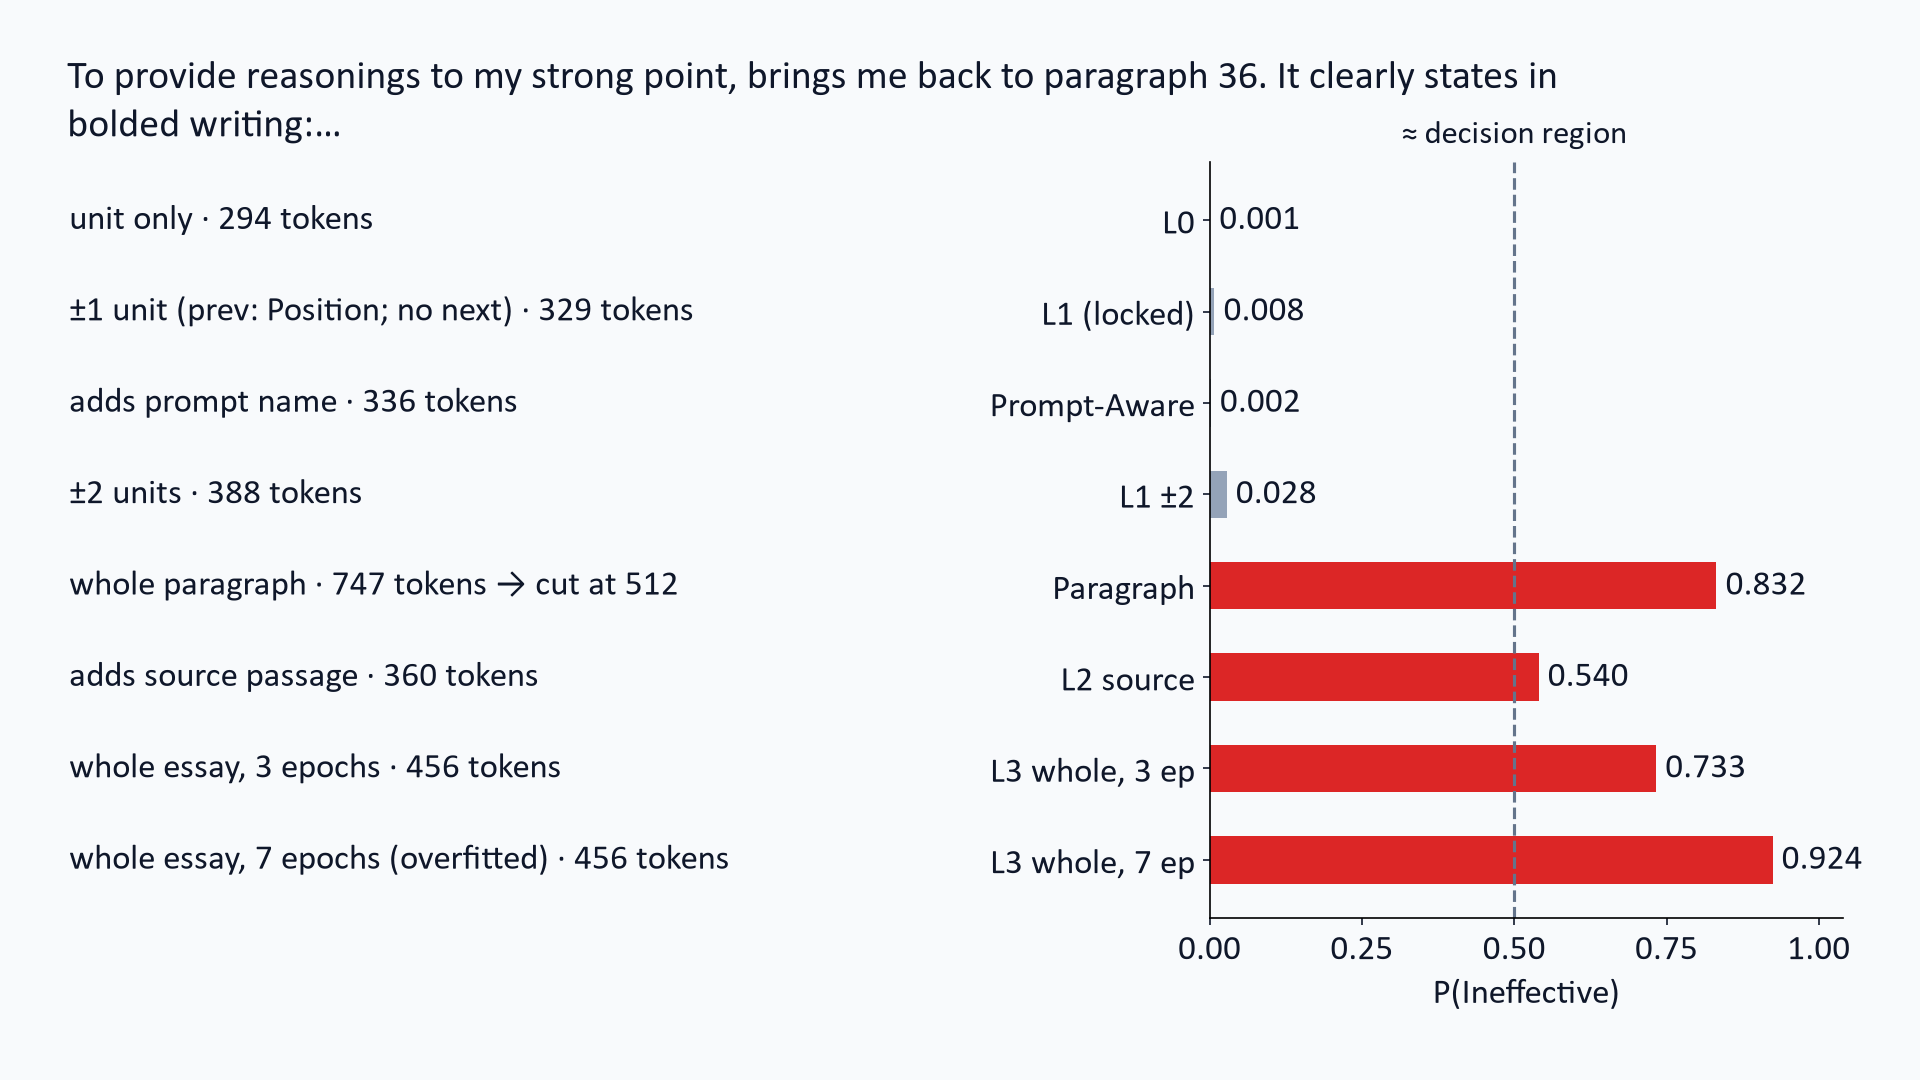

In [6]:
display(Image(filename=str(ROOT / "VIDEO_CA_NHAN/Nguoi_3_TestGovernance_LOPO_Ladder/visuals/v1_case2_ladder.png"), width=1100))

## ⑤ Unseen prompts: LOPO vs in-domain on the same validation essays

In [7]:
r5 = data.table("R5_lopo_vs_indomain_per_class.csv")
rows = []
for prompt, g in r5.groupby("held_out_prompt", sort=False):
    lopo = g[g.setting.str.startswith("LOPO") & g.setting.str.contains("validation essays")].iloc[0]
    dom = g[g.setting.str.startswith("In-domain")].iloc[0]
    rows.append((prompt, lopo["units/essays"], dom.macro_f1, lopo.macro_f1, lopo.macro_f1 - dom.macro_f1))
show(pd.DataFrame(rows, columns=["held-out prompt", "units / essays", "in-domain", "LOPO", "gap"]),
     {"in-domain": "{:.4f}", "LOPO": "{:.4f}", "gap": "{:+.4f}"})
print("Paper (Table 6.7) rounds the gaps to -0.092 / -0.025 / -0.048; reproduce_results.py prints -0.091 for Cowboy (-0.0915).")

held-out prompt,units / essays,in-domain,LOPO,gap
A Cowboy Who Rode the Waves,1030 / 134,0.4755,0.3840,-0.0915
Summer projects,2074 / 177,0.5076,0.4827,-0.0249
Distance learning,3533 / 283,0.5757,0.5279,-0.0478


Paper (Table 6.7) rounds the gaps to -0.092 / -0.025 / -0.048; reproduce_results.py prints -0.091 for Cowboy (-0.0915).


Full raw-row trace of case 2 (input text and token count per level): `VAN_DAP_4_TIEU_CHI/trace_mau_that/TRACE_MAU_THAT_PIPELINE.html` (local only).